# EDA of llm4ke dataset

Dataset source: [D2KLab/llm4ke](https://github.com/D2KLab/llm4ke)

Each ontology folder under `data/` has three parts:
- `cqs/` — competency questions (English requirements)
- `dm/` — data model / ontology files (`.owl`, `.ttl`, `.rdf`)
- `rq/` — gold SPARQL queries for (some of) those CQs

## 1. Ontology inventory

In [10]:
from pathlib import Path

import pandas as pd
import yaml
from rdflib import OWL, RDF, RDFS, Graph, URIRef

DATA_DIR = Path("../data")
ONTOLOGY_EXTS = {".owl", ".ttl", ".rdf", ".n3", ".nt", ".jsonld"}

In [11]:
def load_description(ont_dir: Path) -> str:
    desc_path = ont_dir / "description.txt"
    if desc_path.exists():
        return desc_path.read_text(encoding="utf-8").strip()
    return "(no description available)"


def count_cqs(ont_dir: Path) -> tuple[int, int]:
    cqs_path = ont_dir / "cqs" / "cqs.yml"
    if not cqs_path.exists():
        return 0, 0
    payload = yaml.safe_load(cqs_path.read_text(encoding="utf-8")) or {}
    cqs = payload.get("ontology", {}).get("cqs", []) or []
    with_rq = sum(1 for cq in cqs if cq.get("rq"))
    return len(cqs), with_rq


def count_rq_files(ont_dir: Path) -> int:
    rq_dir = ont_dir / "rq"
    if not rq_dir.exists():
        return 0
    return sum(1 for p in rq_dir.iterdir() if p.suffix.lower() in {".rq", ".sparql"})


def ontology_stats(ont_dir: Path) -> dict:
    """Parse all ontology serializations under dm/ and count OWL terms."""
    dm_dir = ont_dir / "dm"
    files = sorted(
        p for p in dm_dir.rglob("*") if p.is_file() and p.suffix.lower() in ONTOLOGY_EXTS
    )
    g = Graph()
    parse_errors = []
    for path in files:
        try:
            g.parse(path)
        except Exception as exc:  # noqa: BLE001 — keep inventory robust
            parse_errors.append(f"{path.name}: {exc}")

    classes = {
        c
        for c in set(g.subjects(RDF.type, OWL.Class)) | set(g.subjects(RDF.type, RDFS.Class))
        if isinstance(c, URIRef)
    }
    object_properties = set(g.subjects(RDF.type, OWL.ObjectProperty))
    datatype_properties = set(g.subjects(RDF.type, OWL.DatatypeProperty))

    return {
        "dm_files": len(files),
        "classes": len(classes),
        "object_properties": len(object_properties),
        "datatype_properties": len(datatype_properties),
        "triples": len(g),
        "parse_errors": parse_errors,
    }


def list_ontology_dirs(data_dir: Path) -> list[Path]:
    skip = {"shared"}
    return sorted(
        p for p in data_dir.iterdir() if p.is_dir() and p.name not in skip and not p.name.startswith(".")
    )


rows = []
for ont_dir in list_ontology_dirs(DATA_DIR):
    n_cqs, n_cqs_with_rq = count_cqs(ont_dir)
    stats = ontology_stats(ont_dir)
    rows.append(
        {
            "ontology": ont_dir.name,
            "description": load_description(ont_dir),
            "n_cqs": n_cqs,
            "n_cqs_with_rq": n_cqs_with_rq,
            "n_rq_files": count_rq_files(ont_dir),
            "n_dm_files": stats["dm_files"],
            "n_classes": stats["classes"],
            "n_object_properties": stats["object_properties"],
            "n_datatype_properties": stats["datatype_properties"],
            "n_triples": stats["triples"],
        }
    )

inventory = pd.DataFrame(rows).set_index("ontology")
pd.set_option("display.max_colwidth", 120)
inventory

,description,n_cqs,n_cqs_with_rq,n_rq_files,n_dm_files,n_classes,n_object_properties,n_datatype_properties,n_triples
ontology,,,,,,,,,
DOREMUS,"The DOREMUS ontology aims to represent the main concept around music, with a focus on classical music.",58,52,53,3,216,657,48,5923
DemCare,The ontology has been developed in the framework of the Dem@Care project for representing the experimentation protoc...,107,60,60,4,250,49,66,2293
Odeuropa,The Odeuropa ontology represents odours and their experiences from a Cultural Heritage perspective.,74,74,74,1,13,10,0,98
Polifonia,The Polifonia Ontology Network (PON) provides a modular backbone of music ontologies to address both cultural herita...,361,0,0,15,216,256,43,4429
SILKNOW,(no description available),78,25,30,0,0,0,0,0
awo,(no description available),14,7,7,1,31,5,0,272
noria-o,an Ontology for Anomaly Detection and Incident Management in ICT Systems,26,23,25,2,26,80,55,3704
ontodt,(no description available),14,13,13,1,406,16,1,4266
stuff,(no description available),11,9,9,2,76,35,2,2653


In [12]:
numeric_cols = [
    "n_cqs",
    "n_cqs_with_rq",
    "n_rq_files",
    "n_dm_files",
    "n_classes",
    "n_object_properties",
    "n_datatype_properties",
    "n_triples",
]
display(inventory[numeric_cols].sort_values("n_cqs", ascending=False))

print("\nDescriptions:\n")
for name, desc in inventory["description"].items():
    print(f"• {name}: {desc}\n")

,n_cqs,n_cqs_with_rq,n_rq_files,n_dm_files,n_classes,n_object_properties,n_datatype_properties,n_triples
ontology,,,,,,,,
Polifonia,361,0,0,15,216,256,43,4429
DemCare,107,60,60,4,250,49,66,2293
swo,88,42,42,1,4068,51,5,50258
SILKNOW,78,25,30,0,0,0,0,0
Odeuropa,74,74,74,1,13,10,0,98
DOREMUS,58,52,53,3,216,657,48,5923
noria-o,26,23,25,2,26,80,55,3704
awo,14,7,7,1,31,5,0,272
ontodt,14,13,13,1,406,16,1,4266



Descriptions:

• DOREMUS: The DOREMUS ontology aims to represent the main concept around music, with a focus on classical music.

• DemCare: The ontology has been developed in the framework of the Dem@Care project for representing the experimentation protocol towards diagnostic support and assessment of Dementia in a controlled environment. The aim of the protocol is to provide a brief overview of their health status of the participants during consultation (cognition, behaviours and function), and to correlate the system (sensor) data with the data collected using typical dementia care assessment tools

• Odeuropa: The Odeuropa ontology represents odours and their experiences from a Cultural Heritage perspective.

• Polifonia: The Polifonia Ontology Network (PON) provides a modular backbone of music ontologies to address both cultural heritage and more general queries in the music domain.

• SILKNOW: (no description available)

• awo: (no description available)

• noria-o: an Ontology

**How to read the counts**
- `n_cqs` — competency questions in `cqs/cqs.yml`
- `n_cqs_with_rq` — CQs that link to at least one gold SPARQL file
- `n_rq_files` — SPARQL files on disk under `rq/` (`.rq` / `.sparql`)
- `n_classes` / properties — URI-typed `owl:Class` / `rdfs:Class` and OWL properties after merging all files in `dm/`
- **SILKNOW** has CQs + queries but no local ontology dump (`dm/` is empty)
- **Polifonia** has many CQs and ontology modules, but no gold SPARQL in this dataset
- Class counts can look large when an ontology embeds or merges a big hierarchy (e.g. SWO)

## 2. Competency-question profiling

CQs are the main **input** for LLM ontology construction. Here we measure:
- length (words)
- template placeholders like `[this animal]`
- multi-part questions (more than one `?`)
- whether a gold SPARQL link exists
- thematic `group` labels when present

In [13]:
import re
from collections import Counter

import matplotlib.pyplot as plt

PLACEHOLDER_RE = re.compile(r"\[[^\]]+\]")


def load_cq_table(data_dir: Path) -> pd.DataFrame:
    rows = []
    for ont_dir in list_ontology_dirs(data_dir):
        cqs_path = ont_dir / "cqs" / "cqs.yml"
        if not cqs_path.exists():
            continue
        payload = yaml.safe_load(cqs_path.read_text(encoding="utf-8")) or {}
        for cq in payload.get("ontology", {}).get("cqs", []) or []:
            question = (cq.get("question") or "").strip()
            placeholders = PLACEHOLDER_RE.findall(question)
            rows.append(
                {
                    "ontology": ont_dir.name,
                    "cq_id": cq.get("ID"),
                    "question": question,
                    "group": cq.get("group") or None,
                    "has_rq": bool(cq.get("rq")),
                    "n_rq": len(cq.get("rq") or []),
                    "n_chars": len(question),
                    "n_words": len(question.split()),
                    "n_placeholders": len(placeholders),
                    "placeholders": placeholders,
                    "n_question_marks": question.count("?"),
                    "is_multipart": question.count("?") > 1,
                    "has_placeholder": len(placeholders) > 0,
                }
            )
    return pd.DataFrame(rows)


cqs = load_cq_table(DATA_DIR)
print(f"Loaded {len(cqs)} competency questions across {cqs['ontology'].nunique()} ontologies")
cqs.head()

Loaded 831 competency questions across 10 ontologies


,ontology,cq_id,question,group,has_rq,n_rq,n_chars,n_words,n_placeholders,placeholders,n_question_marks,is_multipart,has_placeholder
0,DOREMUS,<CQId>,"On the MLA mailing list, one asked the following question ""A professor at my university asked me today if I could fi...",A. In the Wild,True,1,191,36,0,[],0,False,False
1,DOREMUS,<CQId>,Which works have been composed by Mozart ?,B. Works and Expressions,True,1,42,8,0,[],1,False,False
2,DOREMUS,<CQId>,Which works have been composed in 1836 ?,B. Works and Expressions,True,1,40,8,0,[],1,False,False
3,DOREMUS,<CQId>,Which works have been written for string quartet?,B. Works and Expressions,True,1,49,8,0,[],1,False,False
4,DOREMUS,<CQId>,What works are linked to a particular work and what type of link connect them?,B. Works and Expressions,True,1,78,15,0,[],1,False,False


In [14]:
cq_summary = (
    cqs.groupby("ontology", sort=True)
    .agg(
        n_cqs=("cq_id", "count"),
        pct_with_rq=("has_rq", "mean"),
        pct_with_placeholder=("has_placeholder", "mean"),
        pct_multipart=("is_multipart", "mean"),
        median_words=("n_words", "median"),
        mean_words=("n_words", "mean"),
        max_words=("n_words", "max"),
        n_groups=("group", lambda s: s.dropna().nunique()),
    )
    .join(inventory[["n_dm_files", "n_classes", "n_triples"]])
    .assign(
        pct_with_rq=lambda d: (100 * d["pct_with_rq"]).round(1),
        pct_with_placeholder=lambda d: (100 * d["pct_with_placeholder"]).round(1),
        pct_multipart=lambda d: (100 * d["pct_multipart"]).round(1),
        mean_words=lambda d: d["mean_words"].round(1),
    )
    .sort_values("n_cqs", ascending=False)
)

cq_summary

,n_cqs,pct_with_rq,pct_with_placeholder,pct_multipart,median_words,mean_words,max_words,n_groups,n_dm_files,n_classes,n_triples
ontology,,,,,,,,,,,
Polifonia,361,0.0,6.1,5.8,10.0,12.3,114,3,15,216,4429
DemCare,107,56.1,0.0,0.0,8.0,9.1,21,0,4,250,2293
swo,88,47.7,98.9,1.1,8.0,8.1,17,0,1,4068,50258
SILKNOW,78,32.1,0.0,0.0,11.0,11.2,32,16,0,0,0
Odeuropa,74,100.0,70.3,0.0,11.0,10.8,18,7,1,13,98
DOREMUS,58,89.7,0.0,0.0,15.0,16.4,39,6,3,216,5923
noria-o,26,88.5,0.0,0.0,10.0,11.5,19,0,2,26,3704
awo,14,50.0,57.1,0.0,8.0,8.0,15,0,1,31,272
ontodt,14,92.9,100.0,0.0,11.5,11.8,16,0,1,406,4266


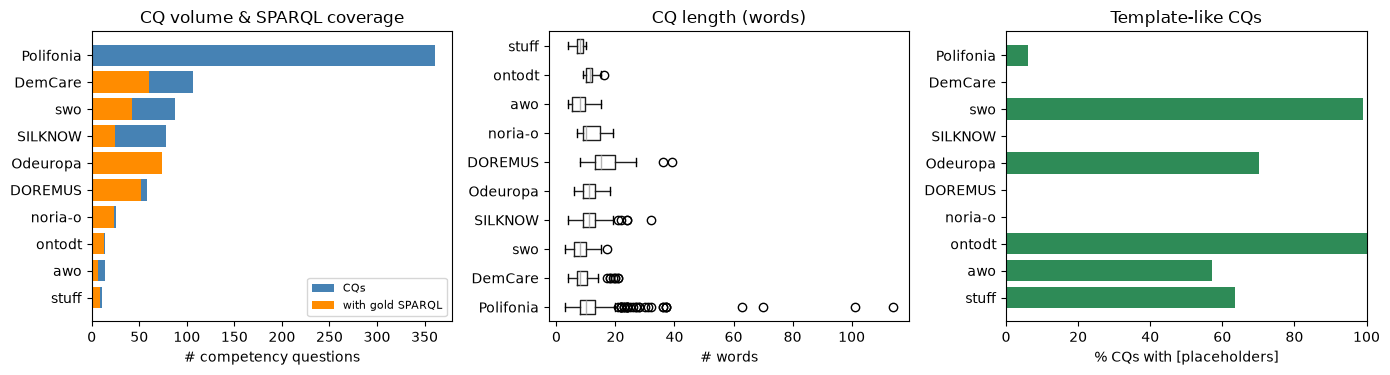

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# CQ volume + SPARQL coverage
cover = cq_summary.sort_values("n_cqs")
axes[0].barh(cover.index, cover["n_cqs"], color="steelblue", label="CQs")
axes[0].barh(
    cover.index,
    (cover["n_cqs"] * cover["pct_with_rq"] / 100).round().astype(int),
    color="darkorange",
    label="with gold SPARQL",
)
axes[0].set_xlabel("# competency questions")
axes[0].set_title("CQ volume & SPARQL coverage")
axes[0].legend(loc="lower right", fontsize=8)

# Word-length distributions
order = cq_summary.index.tolist()
plot_df = cqs.copy()
plot_df["ontology"] = pd.Categorical(plot_df["ontology"], categories=order, ordered=True)
plot_df.boxplot(column="n_words", by="ontology", ax=axes[1], vert=False, grid=False)
axes[1].set_title("CQ length (words)")
axes[1].set_xlabel("# words")
axes[1].set_ylabel("")
fig.suptitle("")  # remove pandas' default boxplot super-title

# Placeholder rate
axes[2].barh(cover.index, cover["pct_with_placeholder"], color="seagreen")
axes[2].set_xlabel("% CQs with [placeholders]")
axes[2].set_title("Template-like CQs")
axes[2].set_xlim(0, 100)

fig.tight_layout()
plt.show()

In [16]:
# Placeholder inventory + longest / multipart examples
placeholder_counts = Counter(p for ps in cqs["placeholders"] for p in ps)
print("Top placeholders across the dataset:")
for token, count in placeholder_counts.most_common(15):
    print(f"  {count:3d}×  {token}")

print("\nLongest CQs (often compound / story-like):")
display(
    cqs.nlargest(8, "n_words")[["ontology", "cq_id", "n_words", "has_rq", "question"]]
)

print("\nMultipart CQs (>1 question mark):")
multipart = cqs.loc[cqs["is_multipart"], ["ontology", "cq_id", "n_words", "question"]]
print(f"{len(multipart)} total")
display(multipart.head(8))

# Groups only where present
grouped = cqs.dropna(subset=["group"])
if not grouped.empty:
    print("\nTop CQ groups:")
    display(
        grouped.groupby(["ontology", "group"])
        .size()
        .rename("n_cqs")
        .reset_index()
        .sort_values("n_cqs", ascending=False)
        .head(20)
    )

Top placeholders across the dataset:
   39×  [it]
   18×  [this software]
   13×  ['hard']
    9×  [the software]
    7×  ['to-split']
    4×  [this animal]
    4×  [these animals]
    4×  [this data]
    3×  [a datatype X]
    3×  [this colloid]
    2×  [childhood]
    2×  [smell, e.g. sweet]
    2×  [smell, e.g. smoky]
    2×  [smell, e.g. citrus]
    2×  [a datatype quality X]

Longest CQs (often compound / story-like):


,ontology,cq_id,n_words,has_rq,question
524,Polifonia,"Sethus,1_ConflictingTheoreticalInterpretations,CQ2",114,False,"Are the criteria on which these interpretations are based true in the score and, if so, to what extent? What are the..."
525,Polifonia,"Sethus,1_ConflictingTheoreticalInterpretations,CQ3",101,False,"Can one assume that the modal ambiguity evidenced by the analytical interpretations is intended? Harold sees, for ex..."
446,Polifonia,"Sophia,1_MusiciansAndTheirEnvironment,CQ1",70,False,"CQ1. What was the composer’s network (patrons, institutions …)? What is the “intellectual framework” of a musician? ..."
526,Polifonia,"Sethus,1_ConflictingTheoreticalInterpretations,CQ4",63,False,"Apart from Lasso’s possible exegetical intentions, what does this work tell us about the status of the modes at this..."
48,DOREMUS,<CQId>,39,False,Give me the list of concerts recorded by Radio France at the auditorium of the Cité de la Musique in which were used...
518,Polifonia,"Sethus,2_CreateRelevantCorpus,CQ1",37,False,Search operations should be expressed on either raw-level features (eg melodic lines) or higher-level features (eg m...
523,Polifonia,"Sethus,1_ConflictingTheoreticalInterpretations,CQ1",37,False,"To which modes Vide homo has been assigned to in Tonalities? Leonhard, Bernhard, Harold, Siegfried, Frans and Alexan..."
527,Polifonia,"Sethus,3_ConflictingAnalyticalAnnotations,CQ1",37,False,"To which modes Vide homo has been assigned to in Tonalities? Leonhard, Bernhard, Harold, Siegfried, Frans and Alexan..."



Multipart CQs (>1 question mark):
22 total


,ontology,cq_id,n_words,question
373,Polifonia,"Ortenz,1_MusicAndChildhood,CQ1",14,CQ1.2 What are the official sources? What are the sources produced by ordinary people?
393,Polifonia,"Ortenz,2_MusicalSocialNetwork,CQ1",17,What places did muciain Z visited in her career? Where did she perform? Where did she live?
394,Polifonia,"Ortenz,2_MusicalSocialNetwork,CQ2",12,"Did musician X and performer Y ever met? Where, when, and why?,['to-split']"
395,Polifonia,"Ortenz,2_MusicalSocialNetwork,CQ3",36,"In what context the meeting happend? What is the nature of the event? Was it a celebration, a festival, a private ev..."
396,Polifonia,"Ortenz,2_MusicalSocialNetwork,CQ4",30,What is the provenance of the event attendees? What and how they happened to be there? Did they travel to reach the ...
446,Polifonia,"Sophia,1_MusiciansAndTheirEnvironment,CQ1",70,"CQ1. What was the composer’s network (patrons, institutions …)? What is the “intellectual framework” of a musician? ..."
448,Polifonia,"Sophia,2_OriginsAndForm,CQ1",32,"CQ1. What parallels are there between the composition of music and the use of language, e.g. in the use of rhetorica..."
449,Polifonia,"Sophia,2_OriginsAndForm,CQ2",23,"CQ2. Why was a piece of music written to be evocative of something, e.g. the call of a cuckoo? What does music evoke?"



Top CQ groups:


,ontology,group,n_cqs
14,Polifonia,default,194
15,Polifonia,old,95
13,Polifonia,Previous set of CQs,71
1,DOREMUS,B. Works and Expressions,31
12,Odeuropa,G. Texts and images - How smells are represented in texts and images?,21
31,SILKNOW,P. Questions in Spanish,15
10,Odeuropa,E. Practices - What kinds of practices produced smells?,13
6,Odeuropa,A. Smells - What smells were significant in the past?,11
11,Odeuropa,"F. Sites and contexts - Which communities, institutions, or spaces were associated with particular smells?",11
16,SILKNOW,A. Location,9


## 3. Shortlist for LLM ontology construction

Heuristic for a first experiment bench:
- local ontology present (`n_dm_files > 0`) — need gold `dm/` to compare against
- small/medium size (`n_classes` not huge) — easier to inspect generations
- enough CQs, preferably with some gold SPARQL

**Exclude for now:** `SILKNOW` (no local ontology), `swo` (very large), `Polifonia` (huge CQ set, no gold SPARQL, many modules).

In [17]:
EXCLUDE = {"SILKNOW", "swo", "Polifonia"}
MAX_CLASSES = 500

shortlist = (
    cq_summary.loc[~cq_summary.index.isin(EXCLUDE)]
    .query("n_dm_files > 0 and n_classes <= @MAX_CLASSES")
    .assign(
        tier=lambda d: pd.cut(
            d["n_classes"],
            bins=[-1, 50, 150, 500],
            labels=["S — tiny schema", "M — medium", "L — richer"],
        )
    )
    .sort_values(["tier", "n_cqs"])
)

print("Recommended first-pass ontologies:\n")
display(shortlist[
    [
        "tier",
        "n_cqs",
        "pct_with_rq",
        "pct_with_placeholder",
        "median_words",
        "n_classes",
        "n_dm_files",
        "n_triples",
    ]
])

Recommended first-pass ontologies:



,tier,n_cqs,pct_with_rq,pct_with_placeholder,median_words,n_classes,n_dm_files,n_triples
ontology,,,,,,,,
awo,S — tiny schema,14,50.0,57.1,8.0,31,1,272
noria-o,S — tiny schema,26,88.5,0.0,10.0,26,2,3704
Odeuropa,S — tiny schema,74,100.0,70.3,11.0,13,1,98
stuff,M — medium,11,81.8,63.6,8.0,76,2,2653
ontodt,L — richer,14,92.9,100.0,11.5,406,1,4266
DOREMUS,L — richer,58,89.7,0.0,15.0,216,3,5923
DemCare,L — richer,107,56.1,0.0,8.0,250,4,2293


Suggested starter: **awo** (tiny, classic CQs) or **Odeuropa** (full SPARQL coverage, small schema, cultural-heritage domain).


## 4. Deep dive: `awo` (African Wildlife Ontology)

Small teaching ontology — good for reading CQs, gold SPARQL, and the class/property vocabulary side by side.

In [18]:
FOCUS = "awo"
focus_dir = DATA_DIR / FOCUS

focus_cqs = cqs.loc[cqs["ontology"] == FOCUS].copy()
display(focus_cqs[["cq_id", "has_rq", "n_placeholders", "n_words", "question"]])

# Load ontology and list vocabulary
focus_graph = Graph()
for path in sorted((focus_dir / "dm").rglob("*")):
    if path.suffix.lower() in ONTOLOGY_EXTS:
        focus_graph.parse(path)

classes = sorted(
    {
        c
        for c in set(focus_graph.subjects(RDF.type, OWL.Class))
        | set(focus_graph.subjects(RDF.type, RDFS.Class))
        if isinstance(c, URIRef)
    },
    key=str,
)
obj_props = sorted(focus_graph.subjects(RDF.type, OWL.ObjectProperty), key=str)
data_props = sorted(focus_graph.subjects(RDF.type, OWL.DatatypeProperty), key=str)

print(f"\n{FOCUS}: {len(focus_graph)} triples, {len(classes)} classes, "
      f"{len(obj_props)} object properties, {len(data_props)} datatype properties\n")
print("Classes:")
for c in classes:
    label = focus_graph.value(c, RDFS.label)
    comment = focus_graph.value(c, RDFS.comment)
    extra = f" — {label}" if label else ""
    if comment:
        extra += f" | {str(comment)[:80]}"
    print(f"  - {c}{extra}")

print("\nObject properties:")
for p in obj_props:
    print(f"  - {p}")

,cq_id,has_rq,n_placeholders,n_words,question
678,awo_1,True,0,6,Which animal eats which other animal?
679,awo_2,True,1,5,Is [this animal] a herbivore?
680,awo_3,False,1,10,Which plant parts does [this omnivorous or herbivorourus animal] eat?
681,awo_4,True,0,8,Does a lion eat plants or plant parts?
682,awo_5,False,0,9,Is there an animal that does not drink water?
683,awo_6,True,0,4,Which plants eat animals?
684,awo_7,True,1,5,Which animals eat [these animals]?
685,awo_8,True,1,8,Which animals are the predators of [these animals]?
686,awo_9,False,2,7,Are there [these animals] in [this country]?
687,awo_10,False,1,11,Which country do I have to visit to see [these animals]?



awo: 272 triples, 31 classes, 5 object properties, 0 datatype properties

Classes:
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#Berry
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#CarnivorousPlant
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#Elephant
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#FruitingBody
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#Grass
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#Impala | An african antelope http://en.wikipedia.org/wiki/Impala
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#Omnivore
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#Palmtree
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#Phloem
  - http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#PlantParts
  - http://www

In [19]:
# Pair one CQ with its gold SPARQL (when linked in cqs.yml)
focus_payload = yaml.safe_load((focus_dir / "cqs" / "cqs.yml").read_text(encoding="utf-8"))
example = next(cq for cq in focus_payload["ontology"]["cqs"] if cq.get("rq"))
rq_name = example["rq"][0]
rq_text = (focus_dir / "rq" / rq_name).read_text(encoding="utf-8")

print(f"CQ {example.get('ID')}: {example['question']}")
print(f"Gold SPARQL file: rq/{rq_name}\n")
print(rq_text)

# Which ontology IRIs does this query mention?
iris_in_query = set(re.findall(r"<([^>]+)>", rq_text))
prefixed = set(re.findall(r"\b([A-Za-z_][\w]*):([A-Za-z_][\w\-]*)", rq_text))
print("Full IRIs in query:", iris_in_query or "(none)")
print("Prefixed names in query:", sorted({f"{p}:{l}" for p, l in prefixed})[:30])

CQ awo_1: Which animal eats which other animal?
Gold SPARQL file: rq/awo_1.rq

# Which animal eats which other animal?


prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#>
prefix owl: <http://www.w3.org/2002/07/owl#>
prefix : <http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#>

select distinct *
where
{
?eats rdfs:subClassOf :animal, [
a owl:Restriction ;
owl:onProperty :eats;
owl:someValuesFrom ?eaten
] .
?eaten rdfs:subClassOf :animal .
filter(?eats != owl:Nothing)
}

Full IRIs in query: {'http://www.w3.org/2002/07/owl#', 'http://www.w3.org/2000/01/rdf-schema#', 'http://www.meteck.org/teaching/ontologies/AfricanWildlifeOntology1.owl#'}
Prefixed names in query: ['owl:Nothing', 'owl:Restriction', 'owl:onProperty', 'owl:someValuesFrom', 'rdfs:subClassOf']


### Takeaways
- CQs vary a lot: short taxonomy questions (`DemCare`, `awo`) vs long story-like ones (`Polifonia`)
- Placeholders are common in CLaRO/Odeuropa/SWO — the LLM must invent *patterns*, not one-off facts
- Gold SPARQL coverage is uneven → ontology-generation eval can use all shortlisted ontologies; query-generation eval should prefer high `pct_with_rq` (e.g. Odeuropa, DOREMUS, noria-o, ontodt)